# Trabalho, Energia e Momento Linear — Parte II de Física I

### Material de estudo visual — Engenharia Naval, Poli-USP

Este notebook é um **guia de revisão** para os conceitos centrais da segunda parte de Física I: trabalho,
energia, sistemas de partículas, momento linear, colisões e propulsão de foguetes. A ideia não é resolver
exercícios, mas sim **ver** os conceitos acontecerem — com gráficos, animações e comparações lado a lado —
para construir intuição física sólida antes de partir para os problemas.

## Sumário

1. [Trabalho e energia cinética](#1.-Trabalho-e-energia-cinética)
2. [Forças conservativas: energia potencial](#2.-Forças-conservativas:-energia-potencial)
3. [Sistemas de partículas: conservação do momento linear](#3.-Sistemas-de-partículas:-conservação-do-momento-linear)
4. [Sistemas de partículas: colisões](#4.-Sistemas-de-partículas:-colisões)
5. [Sistema de massa variável: propulsão de um foguete](#5.-Sistema-de-massa-variável:-propulsão-de-um-foguete)

> **Como usar este notebook:** execute as células em ordem (`Run All`). Cada seção tem teoria resumida,
> uma ou mais visualizações, e uma caixa de "intuição física" destacando a ideia-chave por trás da matemática.


In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import sympy as sp

# Estilo visual consistente para todo o notebook
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.facecolor'] = '#fbfbfd'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['font.size'] = 11
plt.rcParams['lines.linewidth'] = 2.5
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.framealpha'] = 0.9

# Paleta de cores consistente
COR_AZUL    = '#2563eb'
COR_LARANJA = '#ea580c'
COR_VERDE   = '#16a34a'
COR_ROXO    = '#7c3aed'
COR_VERM    = '#dc2626'
COR_CINZA   = '#6b7280'
PALETA = [COR_AZUL, COR_LARANJA, COR_VERDE, COR_ROXO, COR_VERM]

print("Ambiente configurado. numpy:", np.__version__, "| sympy:", sp.__version__)


Ambiente configurado. numpy: 2.5.3 | sympy: 1.14.0


## 1. Trabalho e energia cinética

O **trabalho** realizado por uma força $\vec F$ sobre uma partícula que se desloca ao longo de uma
trajetória é

$$W = \int \vec F \cdot d\vec r$$

Quando a força é **constante** e o deslocamento é retilíneo, isso se simplifica para

$$W = F\,d\,\cos\theta$$

onde $\theta$ é o ângulo entre a força e o deslocamento. Em uma dimensão, o trabalho é simplesmente a
**área sob a curva** $F(x)$ no gráfico força × posição — seja a força constante ou variável.

### Teorema trabalho-energia cinética

$$W_{total} = \Delta K = K_f - K_i = \tfrac12 m v_f^2 - \tfrac12 m v_i^2$$

O trabalho líquido realizado sobre uma partícula é igual à variação da sua energia cinética. Isso vale
mesmo quando a força não é constante — e é exatamente por isso que a interpretação geométrica como "área"
é tão poderosa: não precisamos resolver a integral analiticamente para saber o resultado.


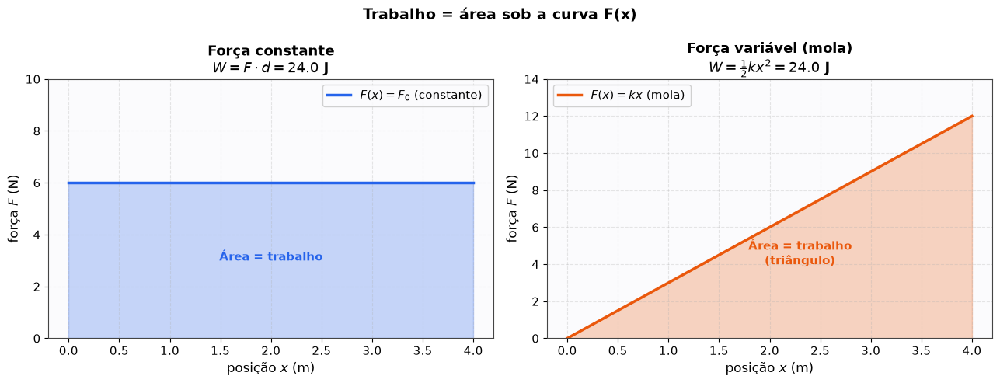

In [3]:
# Trabalho como área sob a curva F(x): força constante vs força variável (mola)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.linspace(0, 4, 400)

# --- Caso 1: força constante ---
F_const = np.full_like(x, 6.0)
axes[0].plot(x, F_const, color=COR_AZUL, label=r'$F(x) = F_0$ (constante)')
axes[0].fill_between(x, F_const, color=COR_AZUL, alpha=0.25)
W_const = 6.0 * 4.0
axes[0].set_title(f'Força constante\n$W = F \\cdot d = {W_const:.1f}$ J')
axes[0].set_xlabel('posição $x$ (m)')
axes[0].set_ylabel('força $F$ (N)')
axes[0].set_ylim(0, 10)
axes[0].legend(loc='upper right')
axes[0].annotate('Área = trabalho', xy=(2, 3), fontsize=11, ha='center',
                  color=COR_AZUL, fontweight='bold')

# --- Caso 2: força de mola F = -kx, trabalho para esticar de 0 a 4 ---
k = 3.0
F_mola = k * x  # magnitude da força que o agente externo aplica (oposta à força restauradora)
axes[1].plot(x, F_mola, color=COR_LARANJA, label=r'$F(x) = kx$ (mola)')
axes[1].fill_between(x, F_mola, color=COR_LARANJA, alpha=0.25)
W_mola = 0.5 * k * 4.0**2
axes[1].set_title(f'Força variável (mola)\n$W = \\frac{{1}}{{2}}kx^2 = {W_mola:.1f}$ J')
axes[1].set_xlabel('posição $x$ (m)')
axes[1].set_ylabel('força $F$ (N)')
axes[1].set_ylim(0, 14)
axes[1].legend(loc='upper left')
axes[1].annotate('Área = trabalho\n(triângulo)', xy=(2.3, 4), fontsize=11, ha='center',
                  color=COR_LARANJA, fontweight='bold')

plt.suptitle('Trabalho = área sob a curva F(x)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


> **Intuição física:** não importa o formato de $F(x)$ — o trabalho é sempre a área "varrida" pela
> força ao longo do caminho. Para uma força constante essa área é um retângulo; para uma mola, um
> triângulo. Pense em "acumular força ao longo da distância", como juntar moedinhas: cada pedacinho
> $F\,dx$ é uma "moeda" de trabalho, e $W$ é a soma (integral) de todas elas.


In [4]:
# Animação: bloco acelerando sob força constante + barra de energia cinética crescendo
m = 2.0       # kg
F = 8.0       # N
a = F / m     # aceleração
x0, xf = 0.0, 10.0
t_total = np.sqrt(2 * (xf - x0) / a)
t = np.linspace(0, t_total, 120)
x_t = x0 + 0.5 * a * t**2
v_t = a * t
K_t = 0.5 * m * v_t**2
K_max = 0.5 * m * (a * t_total)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})

# painel esquerdo: bloco se movendo sob a força
ax1.set_xlim(-0.5, xf + 1)
ax1.set_ylim(-1, 2.5)
ax1.set_xlabel('posição $x$ (m)')
ax1.set_yticks([])
ax1.set_title('Bloco acelerado por força constante $F$')
bloco, = ax1.plot([], [], 's', color=COR_AZUL, markersize=22)
seta = ax1.annotate('', xy=(0, 0), xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', color=COR_LARANJA, lw=3))
texto_v = ax1.text(0.02, 0.9, '', transform=ax1.transAxes, fontsize=11)

# painel direito: barra de energia cinética
ax2.set_xlim(-0.5, 0.5)
ax2.set_ylim(0, K_max * 1.1)
ax2.set_xticks([])
ax2.set_ylabel('Energia cinética $K$ (J)')
ax2.set_title('$K(t) = \\frac{1}{2}mv^2$')
barra = ax2.bar([0], [0], width=0.6, color=COR_VERDE)

def init():
    bloco.set_data([], [])
    return bloco, barra

def animar(i):
    xi = x_t[i]
    bloco.set_data([xi], [0.5])
    seta.xy = (xi + 0.8, 0.5)
    seta.set_position((xi + 0.1, 0.5))
    texto_v.set_text(f'$v$ = {v_t[i]:.2f} m/s\n$K$ = {K_t[i]:.1f} J')
    barra[0].set_height(K_t[i])
    return bloco, barra

anim = animation.FuncAnimation(fig, animar, frames=len(t), init_func=init,
                                interval=40, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim.to_jshtml())


> **Intuição física:** repare como a barra de energia cinética cresce de forma **não linear** com o
> tempo — isso ocorre porque $K \propto v^2$, e a velocidade cresce linearmente no tempo sob aceleração
> constante. O trabalho realizado pela força é exatamente a área sob $F(x)$ neste trajeto, e o teorema
> trabalho-energia garante que esse trabalho é igual ao $K$ final (pois $K_i = 0$).


## 2. Forças conservativas: energia potencial

Uma força é **conservativa** quando o trabalho que ela realiza entre dois pontos não depende do caminho
percorrido — apenas dos pontos inicial e final. Para toda força conservativa existe uma função energia
potencial $U(x)$ tal que

$$F = -\frac{dU}{dx}$$

ou seja, a força aponta sempre na direção em que $U$ **diminui**, com magnitude igual à inclinação
(derivada) de $U$. Dois exemplos clássicos:

- **Gravitacional (perto da superfície):** $U(h) = mgh$
- **Elástica (mola ideal):** $U(x) = \tfrac12 k x^2$

A **energia mecânica total** $E = K + U$ se conserva em um sistema onde só atuam forças conservativas.
Isso nos permite visualizar o movimento como uma "bolinha" rolando dentro de um poço de potencial: onde
$U$ é baixo, $K$ é alto (rápido); onde $U$ é alto, $K$ é baixo (lento) — até os **pontos de retorno**,
onde $K=0$ e toda a energia é potencial.


In [5]:
# Paisagem de energia potencial: poço gravitacional/harmônico com bolinha oscilando (conservação de E)
k_mola = 2.0
m_bola = 1.0
x_pot = np.linspace(-3, 3, 400)
U_pot = 0.5 * k_mola * x_pot**2

E_total = 6.0  # energia mecânica total escolhida
x_max = np.sqrt(2 * E_total / k_mola)  # ponto de retorno

omega = np.sqrt(k_mola / m_bola)
t_osc = np.linspace(0, 2 * np.pi / omega, 150)
x_osc = x_max * np.cos(omega * t_osc)
v_osc = -x_max * omega * np.sin(omega * t_osc)
K_osc = 0.5 * m_bola * v_osc**2
U_osc = 0.5 * k_mola * x_osc**2

fig, (axU, axE) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [2, 1]})

axU.plot(x_pot, U_pot, color=COR_AZUL, label='$U(x) = \\frac{1}{2}kx^2$')
axU.axhline(E_total, color=COR_CINZA, linestyle=':', label=f'$E$ total = {E_total:.1f} J')
axU.set_xlabel('posição $x$ (m)')
axU.set_ylabel('Energia (J)')
axU.set_title('Poço de potencial harmônico')
axU.set_ylim(0, E_total * 1.3)
axU.legend(loc='upper center')
bolinha, = axU.plot([], [], 'o', color=COR_VERM, markersize=16, zorder=5)
linha_K = axU.plot([], [], color=COR_VERM, lw=2, linestyle='-')[0]

axE.set_xlim(-0.5, 1.5)
axE.set_ylim(0, E_total * 1.1)
axE.set_xticks([0, 1]); axE.set_xticklabels(['$K$', '$U$'])
axE.set_title('$K + U = E$ (constante)')
barra_K = axE.bar([0], [0], width=0.6, color=COR_VERDE, label='$K$')
barra_U = axE.bar([1], [0], width=0.6, color=COR_LARANJA, label='$U$')
axE.legend(loc='upper right')

def animar_pot(i):
    xi, Ui, Ki = x_osc[i], U_osc[i], K_osc[i]
    bolinha.set_data([xi], [Ui])
    linha_K.set_data([xi, xi], [Ui, Ui + Ki])
    barra_K[0].set_height(Ki)
    barra_U[0].set_height(Ui)
    return bolinha, linha_K, barra_K, barra_U

anim2 = animation.FuncAnimation(fig, animar_pot, frames=len(t_osc), interval=40, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim2.to_jshtml())


In [6]:
# Poço de potencial com dupla cavidade (forma arbitrária) -- pontos de retorno e equilíbrios
x_dc = np.linspace(-2.5, 2.5, 500)
U_dc = x_dc**4 - 4 * x_dc**2 + 2  # poço duplo

# Energia mecânica escolhida de forma a oscilar dentro de UM dos poços
E_dc = -0.5

# Encontrar region onde U <= E_dc perto de x>0 (poço da direita)
mask = (U_dc <= E_dc) & (x_dc > 0)
x_region = x_dc[mask]
x_min_dc, x_max_dc = x_region.min(), x_region.max()

# Resolver numericamente o movimento 1D: m d2x/dt2 = -dU/dx, com dU/dx = 4x^3 - 8x
m_dc = 1.0
dt = 0.01
n_steps = 600
x_arr = np.zeros(n_steps)
v_arr = np.zeros(n_steps)
x_arr[0] = x_min_dc
v_arr[0] = 0.0
for i in range(1, n_steps):
    F_i = -(4 * x_arr[i-1]**3 - 8 * x_arr[i-1])
    a_i = F_i / m_dc
    v_arr[i] = v_arr[i-1] + a_i * dt
    x_arr[i] = x_arr[i-1] + v_arr[i] * dt

U_arr = x_arr**4 - 4 * x_arr**2 + 2
K_arr = 0.5 * m_dc * v_arr**2

fig, (axU2, axE2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [2, 1]})

axU2.plot(x_dc, U_dc, color=COR_AZUL, label='$U(x)$ (poço duplo)')
axU2.axhline(E_dc, color=COR_CINZA, linestyle=':', label=f'$E$ = {E_dc:.1f} J')
axU2.set_ylim(-3, 6)
axU2.set_xlabel('posição $x$ (m)')
axU2.set_ylabel('Energia (J)')
axU2.set_title('Poço de potencial com dupla cavidade')
axU2.legend(loc='upper center')
# marca os mínimos (equilíbrio estável) e máximo central (equilíbrio instável)
axU2.plot([-np.sqrt(2), np.sqrt(2)], [-2, -2], 'v', color=COR_VERDE, markersize=10)
axU2.plot([0], [2], '^', color=COR_VERM, markersize=10)
axU2.annotate('equilíbrio\nestável', xy=(np.sqrt(2), -2), xytext=(1.6, -2.7),
              fontsize=9, color=COR_VERDE, ha='center')
axU2.annotate('equilíbrio\ninstável', xy=(0, 2), xytext=(0, 3.2),
              fontsize=9, color=COR_VERM, ha='center')
bolinha2, = axU2.plot([], [], 'o', color=COR_VERM, markersize=16, zorder=5)

axE2.set_xlim(-0.5, 1.5)
axE2.set_ylim(-3, 6)
axE2.set_xticks([0, 1]); axE2.set_xticklabels(['$K$', '$U$'])
axE2.set_title('$K + U = E$ (constante)')
barra_K2 = axE2.bar([0], [0], width=0.6, color=COR_VERDE, bottom=-3)
barra_U2 = axE2.bar([1], [0], width=0.6, color=COR_LARANJA, bottom=-3)

def animar_dc(i):
    idx = i * 4
    xi, Ui, Ki = x_arr[idx], U_arr[idx], K_arr[idx]
    bolinha2.set_data([xi], [Ui])
    barra_K2[0].set_height(Ki)
    barra_U2[0].set_height(Ui + 3)
    return bolinha2, barra_K2, barra_U2

anim3 = animation.FuncAnimation(fig, animar_dc, frames=n_steps // 4, interval=30, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim3.to_jshtml())


> **Intuição física:** a **inclinação** de $U(x)$ é (menos) a força: onde o gráfico de $U$ é mais
> "íngreme", a força restauradora é mais intensa; onde $U$ é "plano" ($dU/dx=0$), não há força — são os
> **pontos de equilíbrio**. Mínimos de $U$ são equilíbrios **estáveis** (a bolinha tende a voltar); máximos
> são **instáveis** (um pequeno empurrão a afasta cada vez mais). Os **pontos de retorno** (onde a linha
> $E$ cruza $U(x)$) são onde toda a energia é potencial e a velocidade é momentaneamente zero.


## 3. Sistemas de partículas: conservação do momento linear

Para um sistema de partículas de massas $m_i$ e velocidades $\vec v_i$, definimos:

- **Centro de massa:** $\displaystyle \vec r_{cm} = \frac{\sum_i m_i \vec r_i}{\sum_i m_i}$
- **Momento linear total:** $\displaystyle \vec P = \sum_i m_i \vec v_i = M \vec v_{cm}$

Se a **resultante das forças externas** sobre o sistema é nula (sistema isolado), então $\vec P$ se
conserva:

$$\vec P_{antes} = \vec P_{depois}$$

Isso vale mesmo que forças internas complicadas (explosões, atritos internos, colisões) atuem entre as
partes do sistema — pois forças internas sempre aparecem em pares ação-reação que se cancelam na soma total.


In [7]:
# Conservação do momento: "explosão" de um objeto em dois fragmentos
m1, m2 = 2.0, 1.0      # kg
v_antes = 0.0           # objeto em repouso antes da explosão
v1f = -3.0               # velocidade final do fragmento 1 (m/s)
v2f = -m1 * v1f / m2     # obtido impondo conservação do momento: m1 v1f + m2 v2f = 0

t1 = np.linspace(0, 2, 80)
x1_0, x2_0 = 0.0, 0.0
x1 = x1_0 + v1f * t1
x2 = x2_0 + v2f * t1

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [2, 1]})

axA.set_xlim(-8, 8)
axA.set_ylim(-1, 1.5)
axA.set_yticks([])
axA.set_xlabel('posição (m)')
axA.set_title('"Explosão": fragmentos se afastam')
p1, = axA.plot([], [], 'o', color=COR_AZUL, markersize=18, label=f'$m_1$={m1} kg')
p2, = axA.plot([], [], 'o', color=COR_LARANJA, markersize=14, label=f'$m_2$={m2} kg')
seta1 = axA.annotate('', xy=(0,0.6), xytext=(0,0.6), arrowprops=dict(arrowstyle='->', color=COR_AZUL, lw=3))
seta2 = axA.annotate('', xy=(0,0.6), xytext=(0,0.6), arrowprops=dict(arrowstyle='->', color=COR_LARANJA, lw=3))
axA.axvline(0, color=COR_CINZA, linestyle=':')
axA.legend(loc='upper right')

axB.set_xlim(-0.5, 2.5)
Pmax = max(abs(m1*v1f), abs(m2*v2f)) * 1.3
axB.set_ylim(-Pmax, Pmax)
axB.set_xticks([0, 1, 2]); axB.set_xticklabels(['$p_1$', '$p_2$', '$P_{total}$'])
axB.set_title('Momento de cada parte e soma total')
axB.axhline(0, color='black', lw=1)
barP = axB.bar([0, 1, 2], [0, 0, 0], color=[COR_AZUL, COR_LARANJA, COR_VERDE])

def animar_exp(i):
    x1i, x2i = x1[i], x2[i]
    p1.set_data([x1i], [0.6])
    p2.set_data([x2i], [0.3])
    seta1.set_position((x1i - np.sign(v1f)*0.9, 0.6)); seta1.xy = (x1i, 0.6)
    seta2.set_position((x2i - np.sign(v2f)*0.9, 0.3)); seta2.xy = (x2i, 0.3)
    p1_mom = m1 * v1f
    p2_mom = m2 * v2f
    barP[0].set_height(p1_mom)
    barP[1].set_height(p2_mom)
    barP[2].set_height(p1_mom + p2_mom)
    return p1, p2, barP

anim4 = animation.FuncAnimation(fig, animar_exp, frames=len(t1), interval=45, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim4.to_jshtml())


> **Intuição física:** antes da "explosão" o momento total é zero (objeto parado). Depois, os dois
> fragmentos saem em direções opostas — mas repare que a barra de $P_{total}$ permanece **exatamente em
> zero** durante toda a animação: o momento de um fragmento cancela exatamente o do outro, porque
> $m_1 v_1' = -m_2 v_2'$. É o mesmo princípio por trás do recuo de uma arma de fogo ou do empurrão de um
> patinador contra o outro.


In [8]:
# Centro de massa de dois corpos com trajetórias complexas
t2 = np.linspace(0, 10, 300)

m_a, m_b = 3.0, 1.0
# Corpo A: oscila e deriva; Corpo B: oscila com fase diferente e deriva junto
x_a = 0.5 * t2 + 1.2 * np.sin(1.3 * t2)
y_a = 0.8 * np.cos(1.3 * t2)
x_b = 0.5 * t2 - 3.0 * np.sin(1.3 * t2)
y_b = -2.4 * np.cos(1.3 * t2)

x_cm = (m_a * x_a + m_b * x_b) / (m_a + m_b)
y_cm = (m_a * y_a + m_b * y_b) / (m_a + m_b)

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(x_cm.min() - 2, x_cm.max() + 2)
ax.set_ylim(-4, 4)
ax.set_title('Trajetórias individuais complexas, mas o CM segue reta uniforme')
ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')

traj_a, = ax.plot([], [], color=COR_AZUL, alpha=0.5, lw=1.5, label=f'trajetória $m_A$={m_a} kg')
traj_b, = ax.plot([], [], color=COR_LARANJA, alpha=0.5, lw=1.5, label=f'trajetória $m_B$={m_b} kg')
traj_cm, = ax.plot([], [], color=COR_VERDE, lw=2.5, label='trajetória do CM')
pa, = ax.plot([], [], 'o', color=COR_AZUL, markersize=14)
pb, = ax.plot([], [], 'o', color=COR_LARANJA, markersize=10)
pcm, = ax.plot([], [], '*', color=COR_VERDE, markersize=18)
ax.legend(loc='upper left')

def animar_cm(i):
    traj_a.set_data(x_a[:i+1], y_a[:i+1])
    traj_b.set_data(x_b[:i+1], y_b[:i+1])
    traj_cm.set_data(x_cm[:i+1], y_cm[:i+1])
    pa.set_data([x_a[i]], [y_a[i]])
    pb.set_data([x_b[i]], [y_b[i]])
    pcm.set_data([x_cm[i]], [y_cm[i]])
    return traj_a, traj_b, traj_cm, pa, pb, pcm

anim5 = animation.FuncAnimation(fig, animar_cm, frames=0, interval=0)
anim5 = animation.FuncAnimation(fig, animar_cm, frames=len(t2), interval=30, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim5.to_jshtml())


C:\Users\PedroOliveira\AppData\Roaming\Python\Python313\site-packages\matplotlib\animation.py:920: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


> **Intuição física:** mesmo que os dois corpos façam movimentos oscilatórios complicados (como dois
> dançarinos girando um em torno do outro), o **centro de massa do sistema** segue uma trajetória simples
> — aqui, uma linha reta com velocidade constante — porque não há força externa resultante. É por isso
> que, ao analisar sistemas complexos (como um sistema binário de estrelas, ou uma pessoa saltando com
> braços e pernas se movendo), é útil "seguir o CM": ele se comporta como se fosse uma única partícula
> pontual de massa total $M$.


## 4. Sistemas de partículas: colisões

Em toda colisão (sem forças externas), o **momento linear total se conserva**. O que pode ou não se
conservar é a **energia cinética**:

- **Colisão elástica:** conserva $K$ total. Os corpos se separam após a colisão.
- **Colisão inelástica:** não conserva $K$ (parte vira calor, som, deformação).
- **Colisão perfeitamente inelástica:** caso extremo — os corpos **grudam** e seguem juntos.

Para uma colisão elástica 1D entre massas $m_1$ (velocidade $v_1$) e $m_2$ (velocidade $v_2$), as
velocidades finais são:

$$v_1' = \frac{m_1-m_2}{m_1+m_2}v_1 + \frac{2m_2}{m_1+m_2}v_2 \qquad\qquad
v_2' = \frac{2m_1}{m_1+m_2}v_1 + \frac{m_2-m_1}{m_1+m_2}v_2$$

Essas fórmulas vêm diretamente de resolver simultaneamente a conservação do momento e da energia cinética.


In [9]:
# Comparação lado a lado: colisão elástica vs perfeitamente inelástica (1D)
m1c, m2c = 2.0, 1.0
v1i, v2i = 4.0, -2.0

# Elástica
v1e = (m1c - m2c)/(m1c + m2c) * v1i + 2*m2c/(m1c + m2c) * v2i
v2e = 2*m1c/(m1c + m2c) * v1i + (m2c - m1c)/(m1c + m2c) * v2i

# Perfeitamente inelástica
v_fin = (m1c * v1i + m2c * v2i) / (m1c + m2c)

t3 = np.linspace(0, 1.0, 60)   # antes da colisão
t4 = np.linspace(0, 1.2, 70)   # depois da colisão

# posições antes (aproximando-se), colisão em x=0, t_colisao=1.0
x1_before = -v1i * (1.0 - t3) * (-1) if False else None
x1_bef = 0 - v1i * (1 - t3)
x2_bef = 0 - v2i * (1 - t3)

def make_block_anim(v1f, v2f, titulo):
    x1_aft = v1f * t4
    x2_aft = v2f * t4
    x1_full = np.concatenate([x1_bef, x1_aft + x1_bef[-1] - x1_aft[0]])
    x2_full = np.concatenate([x2_bef, x2_aft + x2_bef[-1] - x2_aft[0]])
    return x1_full, x2_full

x1_full, x2_full = make_block_anim(v1e, v2e, 'elastica')
x1_full_i, x2_full_i = make_block_anim(v_fin, v_fin, 'inelastica')

n_frames = len(x1_full)
Ki_total = 0.5*m1c*v1i**2 + 0.5*m2c*v2i**2
Ke_total = np.where(np.arange(n_frames) < len(t3), Ki_total,
                     0.5*m1c*v1e**2 + 0.5*m2c*v2e**2)
Kinel_total = np.where(np.arange(n_frames) < len(t3), Ki_total,
                        0.5*(m1c+m2c)*v_fin**2)

fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={'width_ratios': [2.3, 1]})
axE, axEK = axes[0]
axI, axIK = axes[1]

for ax, titulo in [(axE, 'Colisão ELÁSTICA'), (axI, 'Colisão PERFEITAMENTE INELÁSTICA')]:
    ax.set_xlim(-6, 6); ax.set_ylim(-1, 1.5); ax.set_yticks([])
    ax.set_title(titulo)
    ax.axvline(0, color=COR_CINZA, linestyle=':')

b1e, = axE.plot([], [], 's', color=COR_AZUL, markersize=22, label=f'$m_1$={m1c}kg')
b2e, = axE.plot([], [], 's', color=COR_LARANJA, markersize=16, label=f'$m_2$={m2c}kg')
axE.legend(loc='upper left', fontsize=9)
b1i, = axI.plot([], [], 's', color=COR_AZUL, markersize=22)
b2i, = axI.plot([], [], 's', color=COR_LARANJA, markersize=16)

for ax in (axEK, axIK):
    ax.set_xlim(-0.5, 0.5); ax.set_ylim(0, Ki_total*1.2)
    ax.set_xticks([0]); ax.set_xticklabels(['$K_{total}$'])
axEK.set_title('Energia cinética total')
axIK.set_title('Energia cinética total')
barEK = axEK.bar([0], [0], width=0.6, color=COR_VERDE)
barIK = axIK.bar([0], [0], width=0.6, color=COR_VERM)

def animar_colisao(i):
    b1e.set_data([x1_full[i]], [0.6]); b2e.set_data([x2_full[i]], [0.3])
    b1i.set_data([x1_full_i[i]], [0.6]); b2i.set_data([x2_full_i[i]], [0.3])
    barEK[0].set_height(Ke_total[i])
    barIK[0].set_height(Kinel_total[i])
    return b1e, b2e, b1i, b2i, barEK, barIK

anim6 = animation.FuncAnimation(fig, animar_colisao, frames=n_frames, interval=35, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim6.to_jshtml())


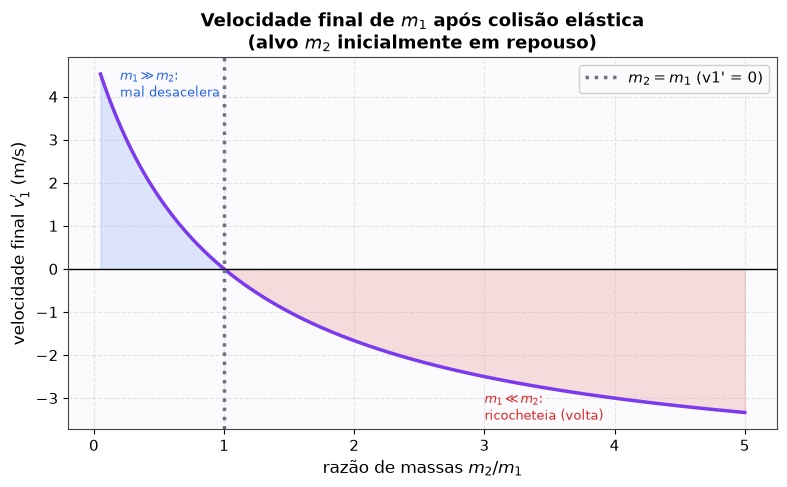

In [10]:
# v1' em função da razão de massas m2/m1 (colisão elástica, alvo m2 inicialmente em repouso)
razao = np.linspace(0.05, 5, 300)   # m2/m1
v1_inicial = 5.0  # m/s, v2_inicial = 0
v1_linha = (1 - razao) / (1 + razao) * v1_inicial

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(razao, v1_linha, color=COR_ROXO)
ax.axhline(0, color='black', lw=1)
ax.axvline(1, color=COR_CINZA, linestyle=':', label='$m_2=m_1$ (v1\' = 0)')
ax.fill_between(razao, v1_linha, 0, where=(v1_linha > 0), color=COR_AZUL, alpha=0.15)
ax.fill_between(razao, v1_linha, 0, where=(v1_linha < 0), color=COR_VERM, alpha=0.15)
ax.set_xlabel('razão de massas $m_2/m_1$')
ax.set_ylabel("velocidade final $v_1'$ (m/s)")
ax.set_title("Velocidade final de $m_1$ após colisão elástica\n(alvo $m_2$ inicialmente em repouso)")
ax.annotate('$m_1 \\gg m_2$:\nmal desacelera', xy=(0.2, 4), fontsize=9, color=COR_AZUL)
ax.annotate('$m_1 \\ll m_2$:\nricocheteia (volta)', xy=(3, -3.5), fontsize=9, color=COR_VERM)
ax.legend()
plt.tight_layout()
plt.show()


> **Intuição física:** se $m_1 \gg m_2$ (bola de boliche batendo num pino), $v_1'$ permanece quase
> igual a $v_1$ — o corpo pesado "nem sente" a colisão. Se $m_1 \ll m_2$ (bolinha de gude batendo numa
> parede), $v_1'$ fica negativo: o corpo leve **ricocheteia** de volta. Quando $m_1 = m_2$, o corpo
> incidente **para completamente** e transfere toda sua velocidade para o alvo — o princípio por trás do
> "pêndulo de Newton" (bolinhas de executivo).


## 5. Sistema de massa variável: propulsão de um foguete

Um foguete é um sistema de **massa variável**: ele ejeta massa (gás de exaustão) continuamente, e é essa
ejeção — não um "empurrão contra o ar" — que gera o impulso. Aplicando conservação do momento ao sistema
foguete + gás ejetado num intervalo $dt$, chega-se à equação do foguete:

$$m\frac{dv}{dt} = v_{ex}\frac{dm}{dt}$$

onde $v_{ex}$ é a velocidade de exaustão relativa ao foguete e $dm/dt$ é a taxa (negativa) de queima de
combustível. Integrando, obtemos a **equação de Tsiolkovsky**:

$$\Delta v = v_{ex}\,\ln\!\left(\frac{m_0}{m_f}\right)$$

onde $m_0$ é a massa inicial (com combustível) e $m_f$ a massa final (sem combustível). Note que $\Delta v$
depende **logaritmicamente** da razão de massas — por isso ganhos marginais de $\Delta v$ custam cada vez
mais combustível, o que motiva o uso de **múltiplos estágios**.


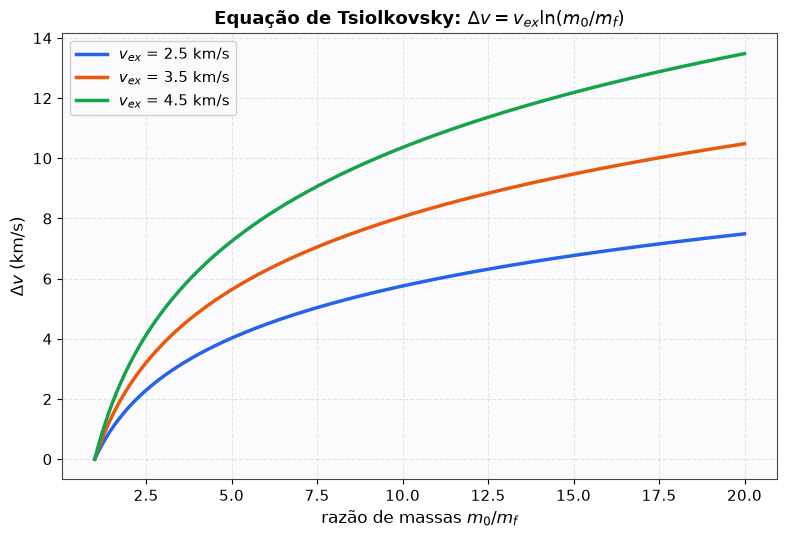

In [11]:
# Delta-v em função da razão de massas, para diferentes velocidades de exaustão
razao_massas = np.linspace(1, 20, 300)
v_exs = [2.5, 3.5, 4.5]  # km/s, típico de propelentes químicos

fig, ax = plt.subplots(figsize=(8, 5.5))
for vex, cor in zip(v_exs, PALETA):
    dv = vex * np.log(razao_massas)
    ax.plot(razao_massas, dv, color=cor, label=f'$v_{{ex}}$ = {vex} km/s')

ax.set_xlabel('razão de massas $m_0/m_f$')
ax.set_ylabel('$\\Delta v$ (km/s)')
ax.set_title('Equação de Tsiolkovsky: $\\Delta v = v_{ex}\\ln(m_0/m_f)$')
ax.legend()
plt.tight_layout()
plt.show()


Delta-v com 1 estágio:    6.91 km/s
Delta-v com 2 estágios:   8.70 km/s  (fase1=1.79 + fase2=6.91)

Ganho relativo ao usar 2 estágios: 26.0%


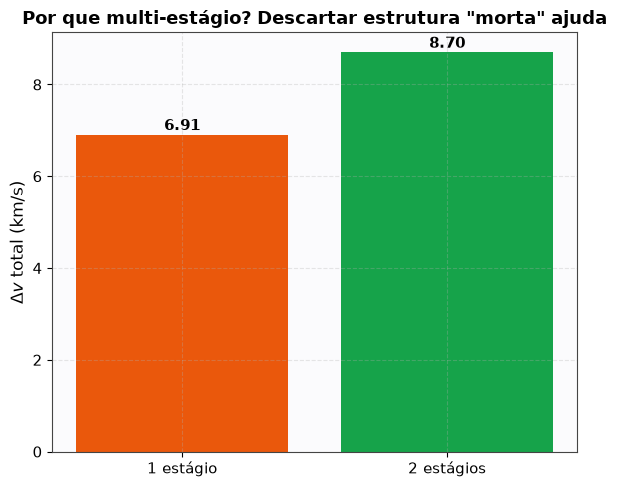

In [12]:
# Exemplo numérico: 1 estagio vs 2 estagios
vex = 3.0  # km/s
m0_total = 100.0   # massa inicial total (toneladas, por exemplo)
m_estrutura_frac = 0.10  # fração estrutural (tanque vazio) de cada estágio

# --- Foguete de 1 estágio ---
# m0 = 100, estrutura = 10% da massa de propelente+estrutura, carga util fixa
m_estrutura_1 = m_estrutura_frac * m0_total
m_final_1 = m_estrutura_1  # tudo que resta é só estrutura (sem carga util para simplificar)
dv_1_estagio = vex * np.log(m0_total / m_final_1)

# --- Foguete de 2 estágios (cada estágio com metade da massa "útil") ---
m_estagio = m0_total / 2
m_estrut_estagio = m_estrutura_frac * m_estagio

# Estágio 1: acelera a massa total (estagio1 + estagio2) até queimar seu propelente
m0_fase1 = m0_total
mf_fase1 = m_estrut_estagio + m_estagio  # sobra estrutura do estágio 1 + estágio 2 inteiro
dv_fase1 = vex * np.log(m0_fase1 / mf_fase1)

# Descarta-se a estrutura do estágio 1; estágio 2 queima seu próprio propelente
m0_fase2 = m_estagio
mf_fase2 = m_estrut_estagio
dv_fase2 = vex * np.log(m0_fase2 / mf_fase2)

dv_2_estagios = dv_fase1 + dv_fase2

print(f"Delta-v com 1 estágio:  {dv_1_estagio:6.2f} km/s")
print(f"Delta-v com 2 estágios: {dv_2_estagios:6.2f} km/s  (fase1={dv_fase1:.2f} + fase2={dv_fase2:.2f})")
print(f"\nGanho relativo ao usar 2 estágios: {100*(dv_2_estagios/dv_1_estagio - 1):.1f}%")

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(['1 estágio', '2 estágios'], [dv_1_estagio, dv_2_estagios], color=[COR_LARANJA, COR_VERDE])
ax.set_ylabel('$\\Delta v$ total (km/s)')
ax.set_title('Por que multi-estágio? Descartar estrutura "morta" ajuda')
for i, v in enumerate([dv_1_estagio, dv_2_estagios]):
    ax.text(i, v + 0.1, f'{v:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


> **Intuição física:** cada estágio carrega consigo o "peso morto" de tanques e motores já vazios dos
> estágios anteriores até descartá-los. Ao **separar os estágios** e descartar a estrutura vazia assim que
> ela deixa de ser útil, o foguete não precisa mais acelerar aquela massa inerte — por isso o $\Delta v$
> total de um foguete multi-estágio supera o de um foguete equivalente de estágio único com a mesma massa
> inicial e carga útil.


In [13]:
# Animação simples: "foguete" acelerando enquanto a massa (tamanho do marcador) diminui
vex_anim = 2.5          # km/s (exaustão)
m0_anim = 10.0           # massa inicial (un. arbitrária)
burn_rate = 0.06         # massa ejetada por passo de tempo
n_frames = int((m0_anim - 1.5) / burn_rate)

massa = np.zeros(n_frames)
veloc = np.zeros(n_frames)
posicao = np.zeros(n_frames)
massa[0] = m0_anim
dt_r = 0.15

for i in range(1, n_frames):
    massa[i] = massa[i-1] - burn_rate
    dv_step = vex_anim * np.log(massa[i-1] / massa[i])
    veloc[i] = veloc[i-1] + dv_step
    posicao[i] = posicao[i-1] + veloc[i-1] * dt_r

fig, (axP, axV) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [2, 1]})

axP.set_xlim(-1, posicao.max() * 1.1)
axP.set_ylim(-1, 1)
axP.set_yticks([])
axP.set_xlabel('posição (un. arbitrária)')
axP.set_title('Foguete acelera enquanto perde massa (tamanho do marcador)')
ponto_fog, = axP.plot([], [], 'o', color=COR_VERM, markersize=20)
rastro, = axP.plot([], [], color=COR_LARANJA, alpha=0.4, lw=4)

axV.set_xlim(0, n_frames * dt_r)
axV.set_ylim(0, veloc.max() * 1.1)
axV.set_xlabel('tempo')
axV.set_ylabel('velocidade')
axV.set_title('$v(t)$ cresce (não linear)')
linha_v, = axV.plot([], [], color=COR_AZUL)

def animar_foguete(i):
    ponto_fog.set_data([posicao[i]], [0])
    ponto_fog.set_markersize(6 + 2.2 * massa[i])
    rastro.set_data(posicao[:i+1], np.zeros(i+1))
    linha_v.set_data(np.arange(i+1) * dt_r, veloc[:i+1])
    return ponto_fog, rastro, linha_v

anim7 = animation.FuncAnimation(fig, animar_foguete, frames=n_frames, interval=40, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim7.to_jshtml())


> **Intuição física:** note que a velocidade cresce **mais rapidamente no final** da queima — isso é
> consequência direta do logaritmo em $\Delta v = v_{ex}\ln(m_0/m_f)$: quando a massa restante $m_f$ já é
> pequena, cada unidade adicional de propelente queimado produz uma razão $m_0/m_f$ relativamente maior,
> logo mais $\Delta v$. É por isso que o estágio final de um foguete, mesmo sendo o menor, costuma ser
> responsável por boa parte do ganho total de velocidade.


---

## Resumo dos conceitos-chave

| Conceito | Ideia central |
|---|---|
| Trabalho | Área sob $F(x)$; $W=\int \vec F\cdot d\vec r$ |
| Teorema trabalho-energia | $W_{total} = \Delta K$ |
| Energia potencial | $F=-dU/dx$; mínimos = equilíbrio estável |
| Energia mecânica | $E=K+U$ se conserva sem forças não-conservativas |
| Momento linear | $\vec P = \sum m_i \vec v_i$; conserva-se se $\sum \vec F_{ext}=0$ |
| Centro de massa | Move-se como se toda a massa estivesse concentrada nele |
| Colisão elástica | Conserva $P$ e $K$ |
| Colisão inelástica | Conserva $P$, não conserva $K$ |
| Equação do foguete | $\Delta v = v_{ex}\ln(m_0/m_f)$ |

Bons estudos! 🚀
